# Hedonic Pricing

We often try to predict the price of an asset from its observable characteristics. This is generally called **hedonic pricing**: How do the unit's characteristics determine its market price?

1. Clean the data `pierce_county_house_sales.csv` and perform some EDA and visualization to get to know the data set.
2. Transform your variables - particularly categorical ones - for use in your regression analysis.
3. Implement an 80/20 train-test split. Put the test data aside.
4. Build some simple linear models that include no transformations or interactions. Fit them, and determine their RMSE and $R^2$ on the both the training and test sets. Which of your models does the best?
5. Make partial correlation plots for each of the numeric variables in your model. Do you notice any significant non-linearities? 
6. Include transformations and interactions of your variables, and build a more complex model that reflects your ideas about how the features of the asset determine its value. Determine its RMSE and $R^2$ on the training and test sets. How does the more complex model your build compare to the simpler ones?
7. Summarize your results from 1 to 6. Have you learned anything about overfitting and underfitting, or model selection?
8. Use the `sklearn.linear_model.Lasso` to regularize your model and select the most predictive features. Which does it select? What are the RMSE and $R^2$? We'll cover the Lasso later in detail in class.

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Amran Belete, Nate Park, Amelia Chen, Lawson Pham

**Date:** 11/9/2026

In [37]:
# Your Phase 1 solution to the problem goes here.
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

df = pd.read_csv('data/pierce_county_house_sales.csv', low_memory=False)

1. Clean the data `pierce_county_house_sales.csv` and perform some EDA and visualization to get to know the data set.


df.shape:
(16814, 19) 

df.dtypes:
sale_date                        str
sale_price                     int64
house_square_feet              int64
attic_finished_square_feet     int64
basement_square_feet           int64
attached_garage_square_feet    int64
detached_garage_square_feet    int64
fireplaces                     int64
hvac_description                 str
exterior                         str
interior                         str
stories                        int64
roof_cover                       str
year_built                     int64
bedrooms                       int64
bathrooms                      int64
waterfront_type                  str
view_quality                     str
utility_sewer                    str
dtype: object 

sale_price: 1014 outliers
house_square_feet: 174 outliers
attic_finished_square_feet: 1104 outliers
basement_square_feet: 2715 outliers
attached_garage_square_feet: 56 outliers
detached_garage_square_feet: 1076 outliers
fireplaces: 5619 outliers


/var/folders/j_/fbn327bs3_x76fjq5ch9hcgc0000gp/T/ipykernel_29617/3916663707.py:25: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = df.select_dtypes(include=["object", "category"]).columns.tolist()


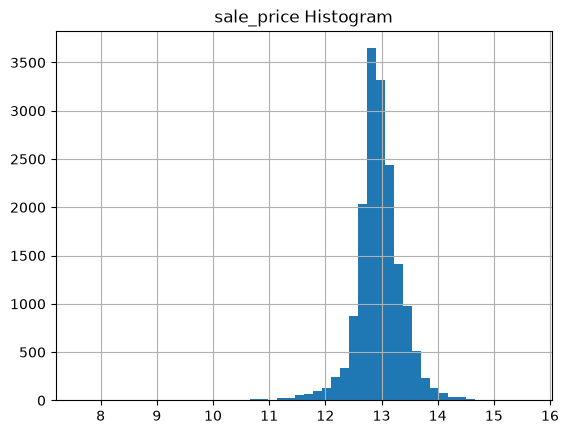

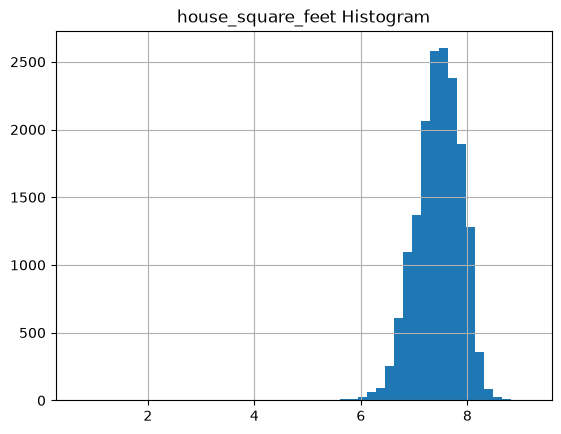

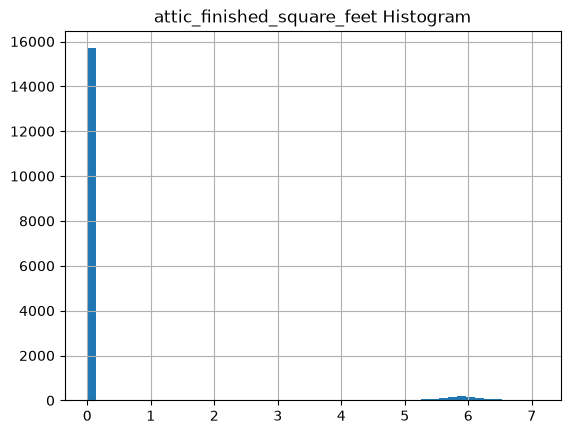

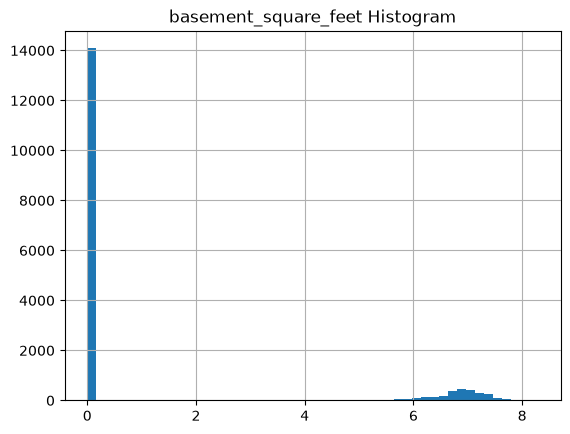

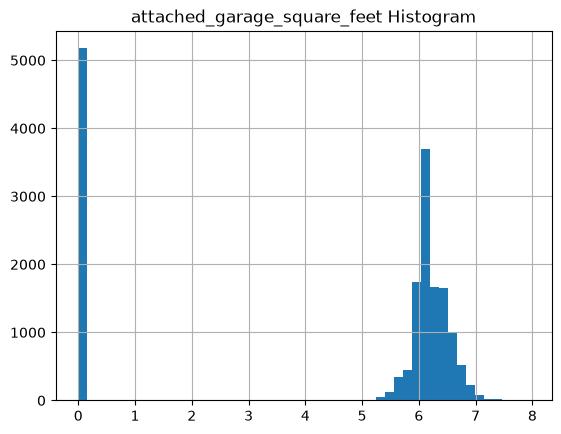

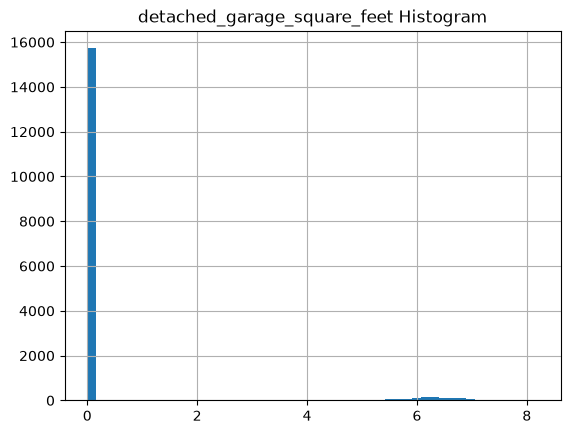

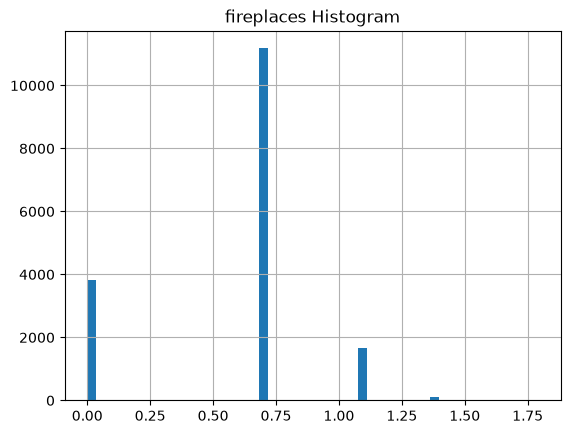

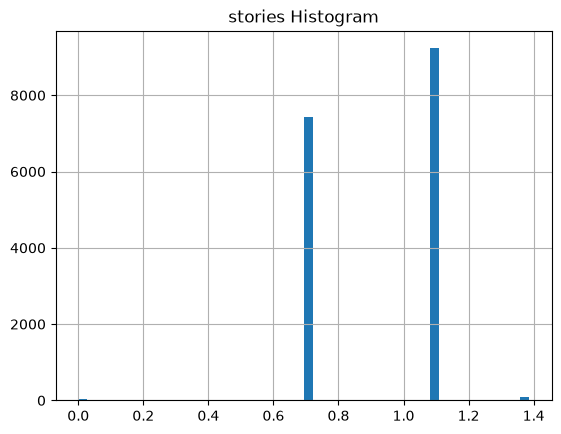

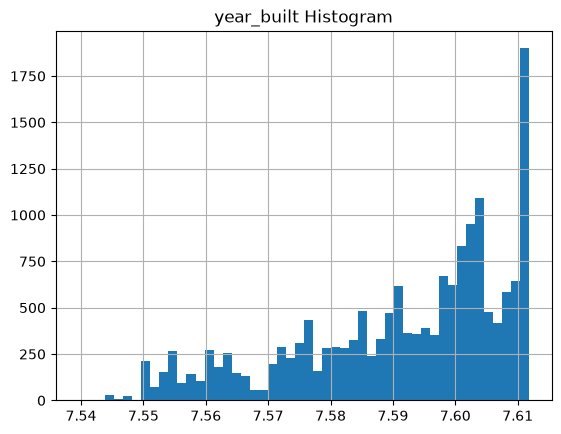

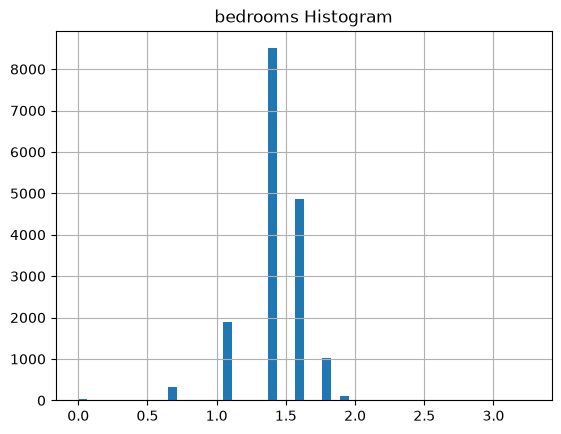

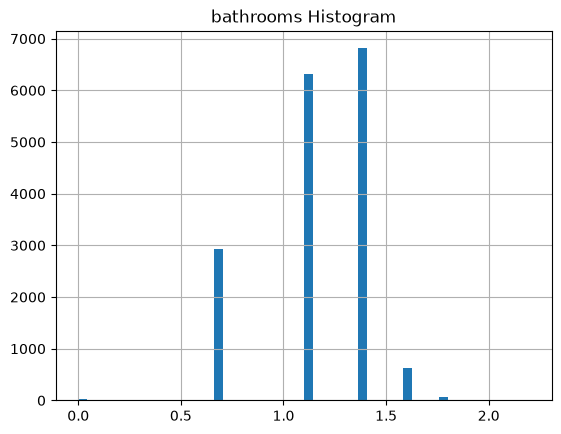

,sale_price,house_square_feet,attic_finished_square_feet,basement_square_feet,attached_garage_square_feet,detached_garage_square_feet,fireplaces,stories,year_built,bedrooms,bathrooms
count,1.679700e+04,16797.000000,16797.000000,16797.000000,16797.000000,16797.000000,16797.000000,16797.000000,16797.000000,16797.000000,16797.000000
mean,4.609776e+05,1880.764363,24.902364,167.925641,364.635292,38.320117,0.889445,1.559028,1980.469012,3.280169,2.318390
std,2.342215e+05,759.762716,101.885451,429.103156,286.374648,164.759289,0.596574,0.511287,33.337722,0.888038,0.826711
min,2.000000e+03,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1880.000000,0.000000,0.000000
25%,3.480000e+05,1320.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,1959.000000,3.000000,2.000000
50%,4.163430e+05,1774.000000,0.000000,0.000000,420.000000,0.000000,1.000000,2.000000,1990.000000,3.000000,2.000000
75%,5.235450e+05,2352.000000,0.000000,0.000000,528.000000,0.000000,1.000000,2.000000,2006.000000,4.000000,3.000000
max,6.130000e+06,9510.000000,1212.000000,4000.000000,2816.000000,3664.000000,5.000000,3.000000,2021.000000,25.000000,8.000000


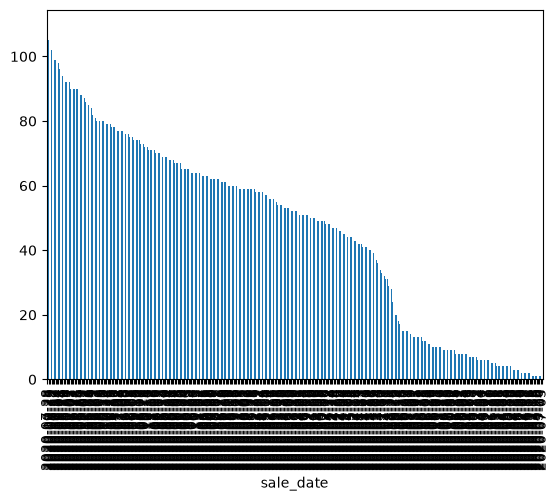

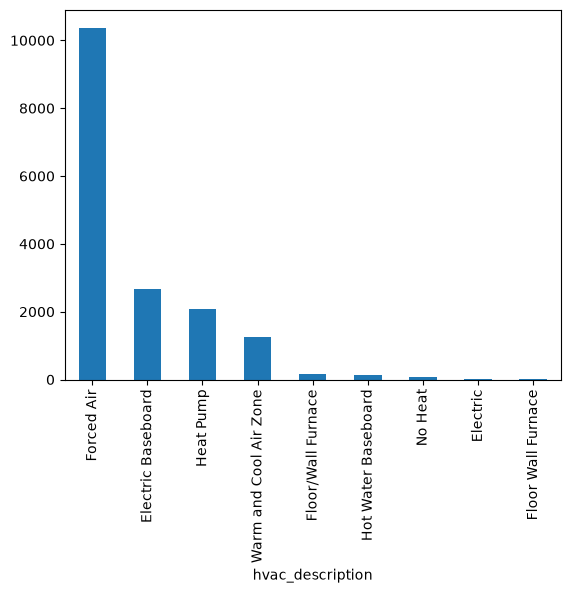

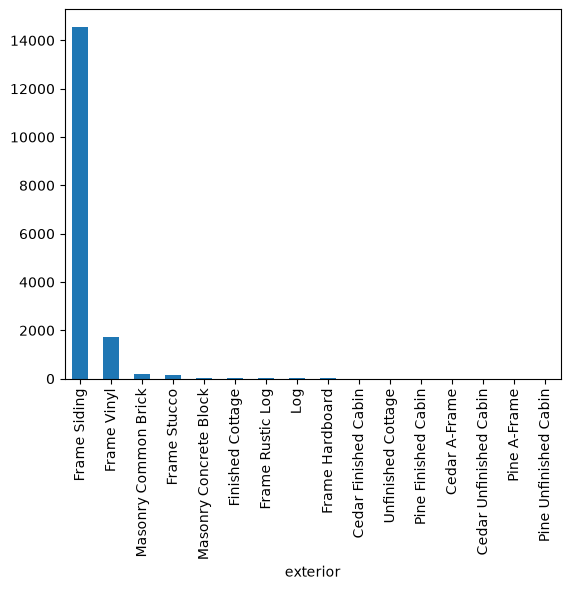

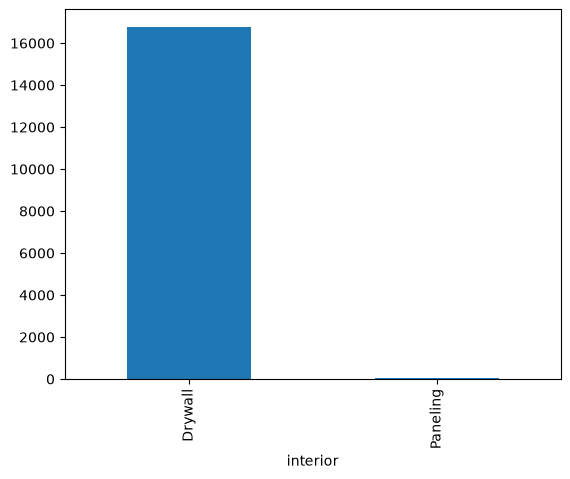

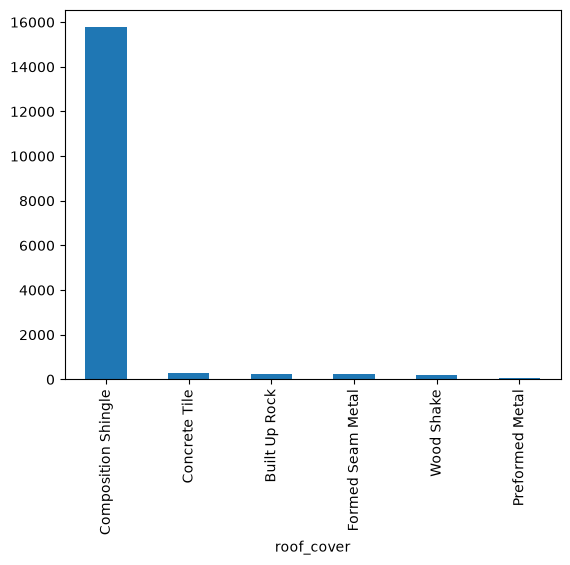

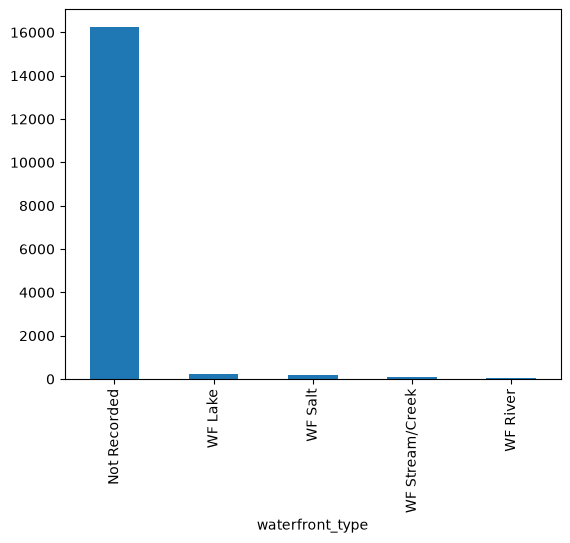

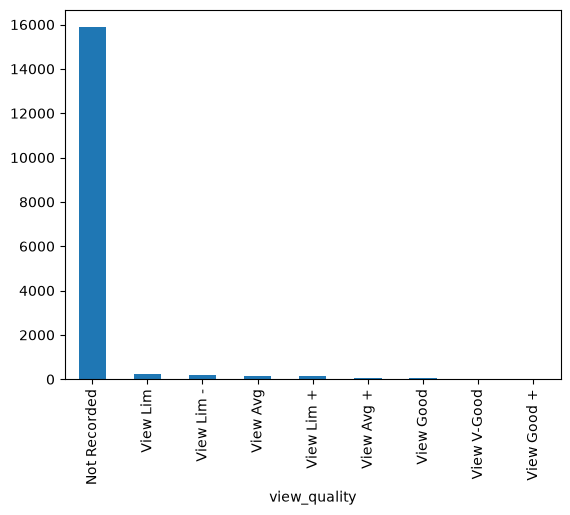

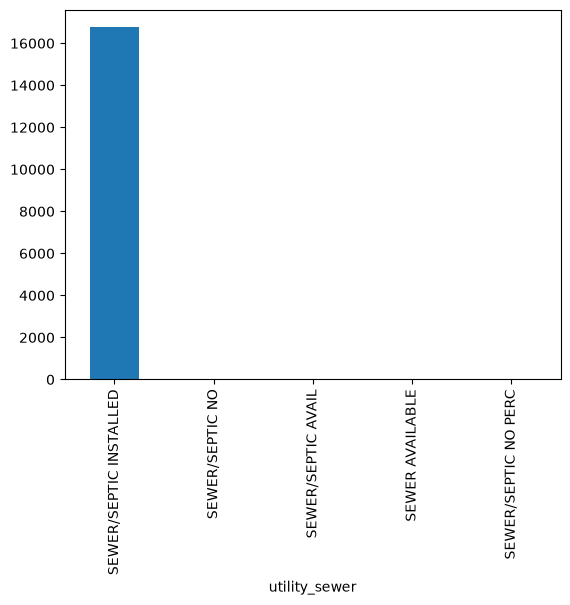

df.shape:
(16749, 19) 



In [38]:
print("df.shape:")
print(df.shape, '\n')

print("df.dtypes:")
print(df.dtypes, '\n')

'''
# Check for missing values in each df
display(df.isna().sum().to_frame("Missing values"))
'''

# Fill missing values in df
df["waterfront_type"] = df["waterfront_type"].fillna("Not Recorded")
df["view_quality"] = df["view_quality"].fillna("Not Recorded")

# Drop rows with missing hvac_description/exterior/interior/roof_cover values
df = df.dropna(subset=["hvac_description", "exterior", "interior", "roof_cover"])

'''
# Check that missing values were filled
display(df.isna().sum().to_frame("Missing values"))
'''

# Separate categorical and numeric variables for EDA
categorical_cols = df.select_dtypes(include=["object", "category"]).columns.tolist()
numeric_cols = df.select_dtypes(include=["number"]).columns.tolist()

'''
print("Categorical variables:", categorical_cols)
print("\nNumeric variables:", numeric_cols)

Categorical variables: ['sale_date', 'hvac_description', 'exterior', 'interior', 'roof_cover', 
'waterfront_type', 'view_quality', 'utility_sewer']

Numeric variables: ['sale_price', 'house_square_feet', 'attic_finished_square_feet', 'basement_square_feet', 
'attached_garage_square_feet', 'detached_garage_square_feet', 'fireplaces', 'stories', 'year_built', 'bedrooms', 'bathrooms']

'''

# Create separate dataframes for the categorical/numeric variables
df_categorical = df[categorical_cols]
df_numeric = df[numeric_cols]

for col in numeric_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df[(df[col] < lower) | (df[col] > upper)]
    print(f"{col}: {len(outliers)} outliers")

'''
df_numeric.hist(figsize=(15, 12), bins=30)
plt.show()

np.log(df["sale_price"]).hist(bins=50)
plt.show()

np.log(df["house_square_feet"]).hist(bins=50)
plt.show()
'''

for col in numeric_cols:
    plt.figure()
    np.log1p(df[col]).hist(bins=50)
    plt.title(f"{col} Histogram")
    plt.show()

display(df_numeric.describe())

for col in categorical_cols:
    plt.figure()
    df[col].value_counts().plot(kind="bar")
    plt.show()

# noticed in the histograms that there are some entries with 0 bedrooms and bathrooms, so drop those rows
df = df[(df["bedrooms"] > 0) & (df["bathrooms"] > 0)]
print("df.shape:")
print(df.shape, '\n')

We noticed that there are 16261 missing values for waterfront_type and 15895 missing values for view_quality. The csv has 16814 entries in total, so a majority of entries are missing these values. Therefore, it is not a vaiable option to drop the missing data, so we are choosing to label it as "not recorded." Additionally, there are 7 missing values for hvac_description, 1 for exterior, 7 for interior, and 8 for roof_cover. Since there are only a few missing values for these variables, and we have a large amount of data in total, we are choosing to drop these rows. There are no missing numeric values.

For outliers, using the IQR on numeric data, we found that there was a high number of outliers. We then used log histograms to understand these outliers. The first issue was that in the histograms for bedrooms/bathrooms, some entries were at 0. It would not make sense for a house to have no bedrooms or bathrooms, so we drop those rows. Next, we found that distributions like house_square_feet and sale_price appeared normally distributed with very steep normal curves. For variables like attic_finished_square_feet, basement_square_feet, attached_garage_square_feet, and detached_garage_square_feet, a lot of might be considered an "outlier" is likely due to the fact that a majority of houses are simply without attic/garages or with very small attics/garages, while a very small amount have large attics/garages. A similar phenomemnon may be occuring with fireplaces, which had 5630 outliers, as we see in the histogram that there are over 10000 entries in one bin only, meanwhile there are between 5000-6000 entries in the other bins combined. When looking at summary statistics, we observed some large jumps between, for example, the 75th percentile to 100th percentile in many of the categories. For example, for house_square_feet, the jump was from 2352 to 9510.

To understand the categorical data better, we used bar charts. We see that in some variables, there is one very common type and a some other very obscure types. This is most evidence in hvac_description, interior/exterior, roof_cover, and utility_sewer. waterfront_type and view_quality have slightly more evenly distribution betwen types, but most entries still fall into 1/2 types.

2. Transform your variables - particularly categorical ones - for use in your regression analysis.


In [39]:

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, Lasso
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, PolynomialFeatures, StandardScaler

target = "sale_price"

categorical_cols = [
    c for c in df.select_dtypes(include=["object", "category"]).columns
    if c != target and c != "sale_date"
]
numeric_cols = [
    c for c in df.select_dtypes(include=["number"]).columns
    if c != target
]

X = df[categorical_cols + numeric_cols]
y = df[target]

# NOTE: we do one-hot encoding in step 4


/var/folders/j_/fbn327bs3_x76fjq5ch9hcgc0000gp/T/ipykernel_29617/825763867.py:12: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  c for c in df.select_dtypes(include=["object", "category"]).columns


3. Implement an 80/20 train-test split. Put the test data aside.


In [40]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)
print(f"Train rows: {len(X_train):,}; test rows: {len(X_test):,}")


Train rows: 13,399; test rows: 3,350


4. Build some simple linear models that include no transformations or interactions. Fit them, and determine their RMSE and $R^2$ on the both the training and test sets. Which of your models does the best?


In [41]:
def make_preprocessor(include_numeric=True, include_categories=True):
    transformers = []

    if include_numeric:
        transformers.append(
            ("numeric", SimpleImputer(strategy="median"), numeric_cols)
        )

    if include_categories:
        categorical_pipeline = Pipeline([
            ("imputer", SimpleImputer(strategy="constant", fill_value="Missing")),
            ("one_hot", OneHotEncoder(handle_unknown="ignore")),
        ])
        transformers.append(
            ("categorical", categorical_pipeline, categorical_cols)
        )

    return ColumnTransformer(transformers, remainder="drop")

def score_model(model, X_train, y_train, X_test, y_test):
    results = []
    for split, features, actual in [
        ("train", X_train, y_train),
        ("test", X_test, y_test),
    ]:
        predicted = model.predict(features)
        results.append({
            "split": split,
            "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
            "R2": r2_score(actual, predicted),
        })
    return pd.DataFrame(results).set_index("split")

simple_models = {
    "Numeric only": Pipeline([
        ("preprocessor", make_preprocessor( include_numeric=True, include_categories=False)),
        ("model", LinearRegression()),
    ]),
    "Categorical only": Pipeline([
        ("preprocessor", make_preprocessor(include_numeric=False, include_categories=True)),
        ("model", LinearRegression()),
    ]),
    "Numeric + categorical": Pipeline([
        ("preprocessor", make_preprocessor( include_numeric=True, include_categories=True)),
        ("model", LinearRegression()),
    ]),
}


simple_scores = {}
for name, model in simple_models.items():
    model.fit(X_train, y_train)
    simple_scores[name] = score_model(model, X_train, y_train, X_test, y_test)
    print(f"\n{name}")
    display(simple_scores[name].round(3))

best_simple = min(simple_scores, key=lambda name: simple_scores[name].loc["test", "RMSE"])
print("Best simple model by test RMSE:", best_simple)




Numeric only


,RMSE,R2
split,,
train,175291.206,0.436
test,183677.367,0.348



Categorical only


,RMSE,R2
split,,
train,187436.435,0.355
test,193969.326,0.273



Numeric + categorical


,RMSE,R2
split,,
train,152472.568,0.573
test,168812.261,0.449


Best simple model by test RMSE: Numeric + categorical


5. Make partial correlation plots for each of the numeric variables in your model. Do you notice any significant non-linearities? 


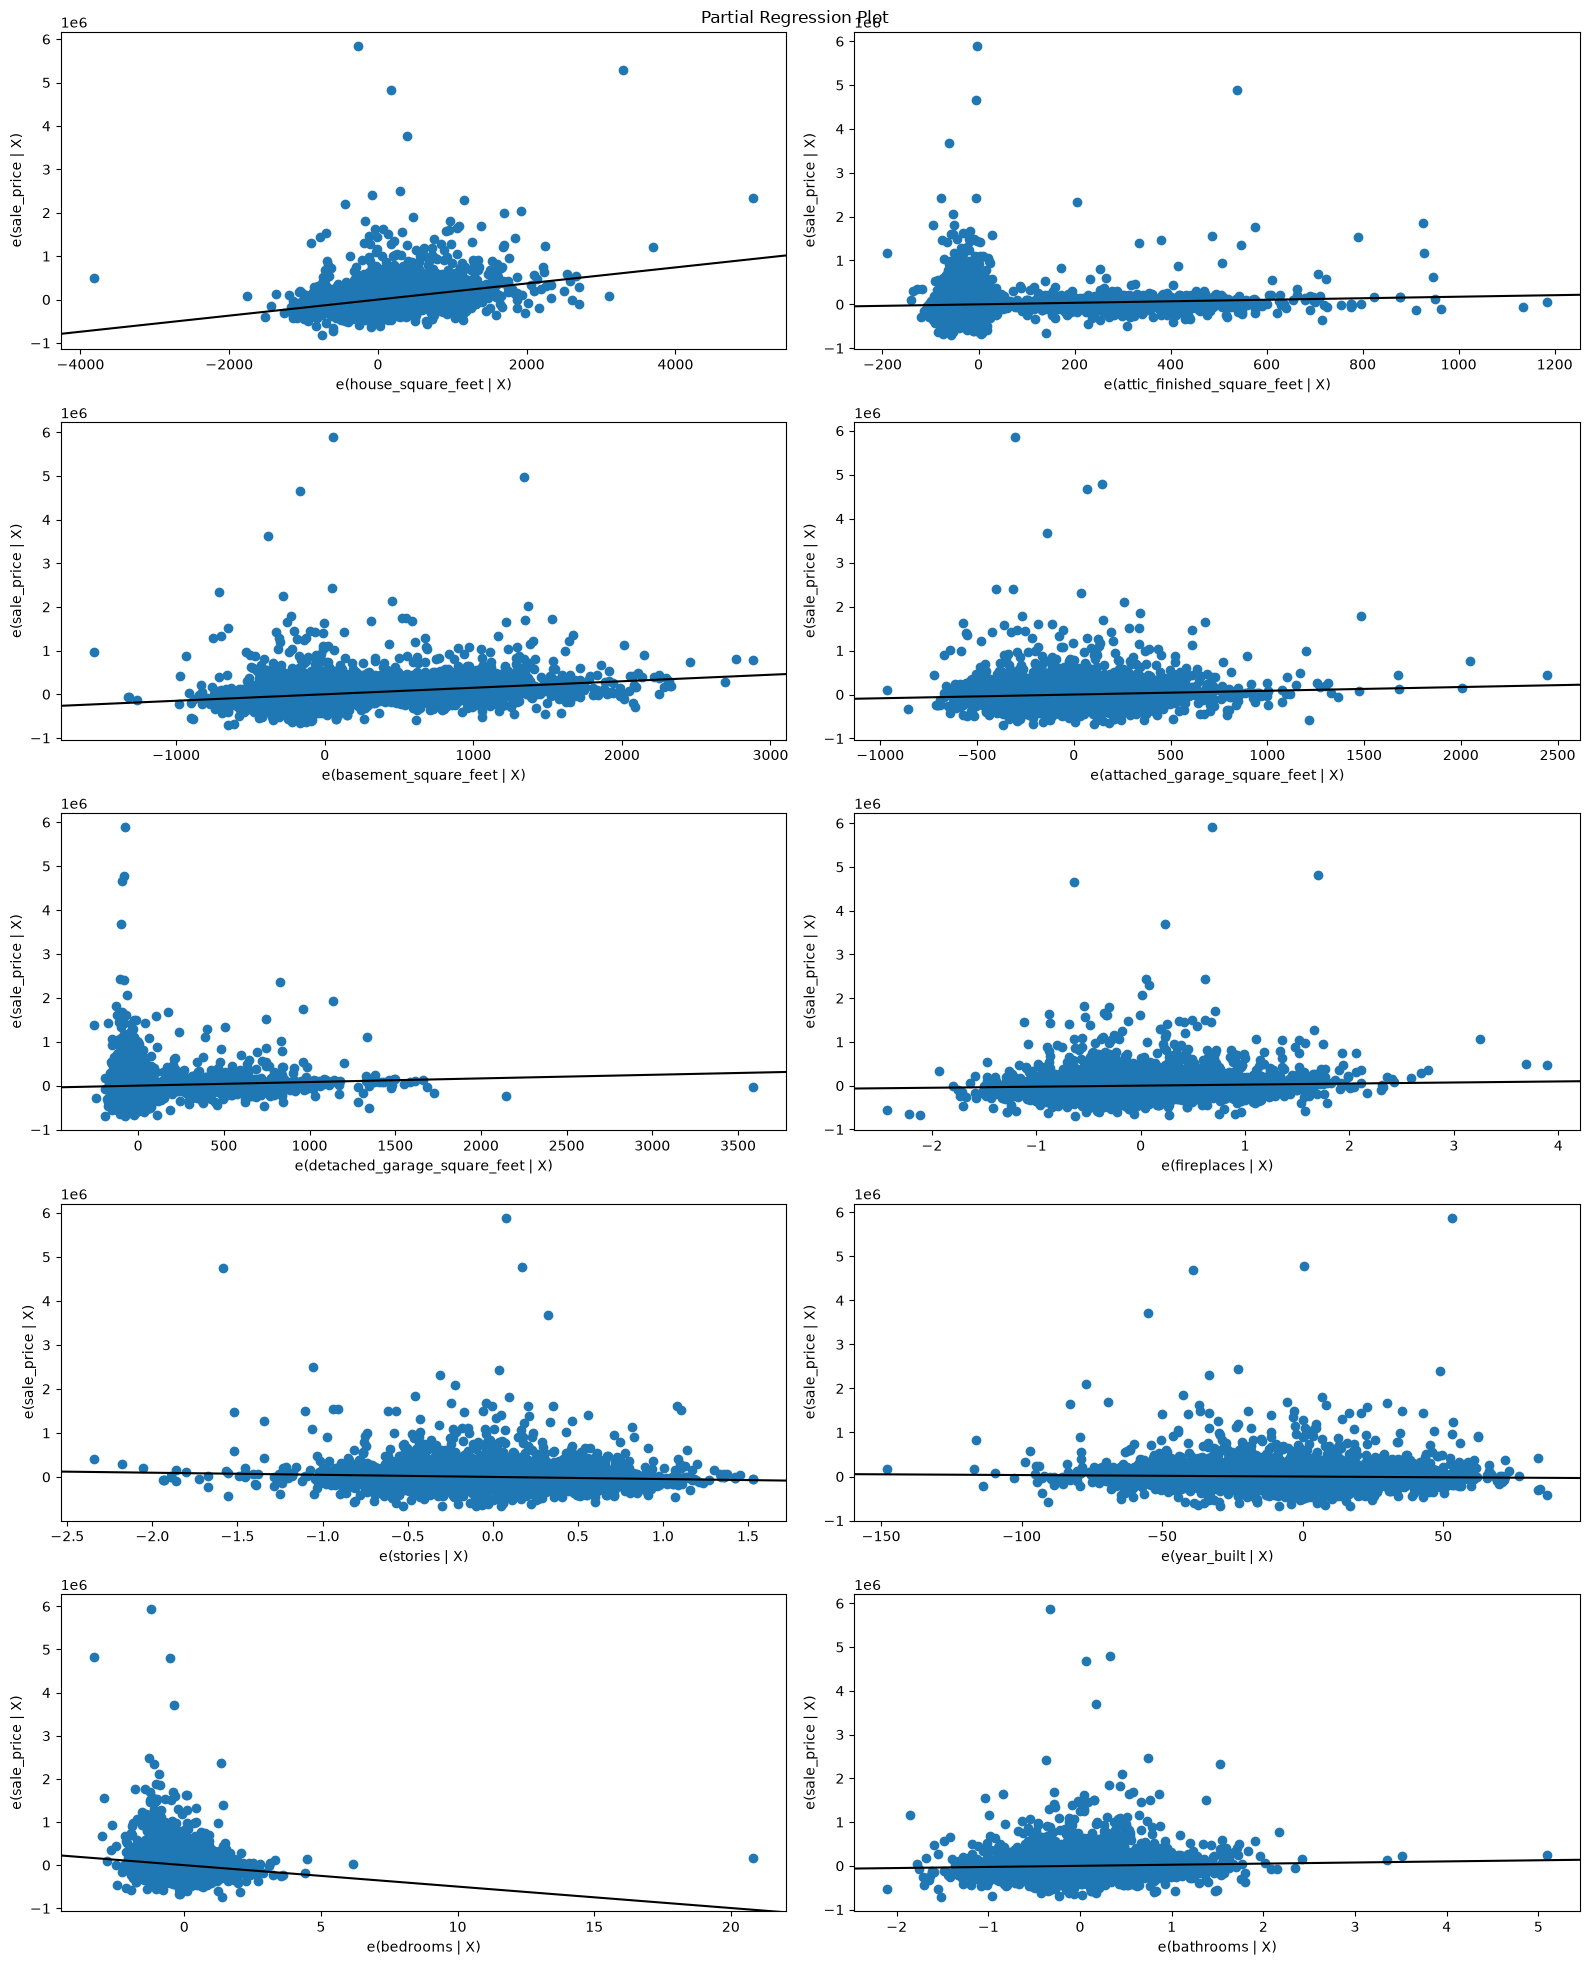

In [42]:
import statsmodels.api as sm
X_num = X_train[numeric_cols].fillna(X_train[numeric_cols].median())
X_num = sm.add_constant(X_num)
model_sm = sm.OLS(y_train, X_num).fit()
fig = plt.figure(figsize=(16, 20))

sm.graphics.plot_partregress_grid(model_sm, exog_idx=numeric_cols, fig=fig)
plt.tight_layout()


plt.show()

We built regression plots for the 10 numeric plots to check whether each ones relationship with the sale price is linear after controlling for the other variables. When looking at the plots, we do not see strong non-linearities since none of the plots show a clear curve such as a U-shape or bend. Most relationships look reasonably linear, with house square footage and basement square footage showing the clearest positive trends.

6. Include transformations and interactions of your variables, and build a more complex model that reflects your ideas about how the features of the asset determine its value. Determine its RMSE and $R^2$ on the training and test sets. How does the more complex model your build compare to the simpler ones?


In [43]:
#make new columns 
def add_features(data):
        data = data.copy()
        data["log_sqft"] = np.log(data["house_square_feet"])
        data["house_age"] = 2020 - data["year_built"].where(data["year_built"] > 0)
        data["age_squared"] = data["house_age"] ** 2
        data["has_basement"] = (data["basement_square_feet"] > 0).astype(int)
        data["has_attic"] = (data["attic_finished_square_feet"] > 0).astype(int)
        data["has_detached_garage"] = (data["detached_garage_square_feet"] > 0).astype(int)
        data["bedrooms"] = data["bedrooms"].where(data["bedrooms"] > 0)
        data["bathrooms"] = data["bathrooms"].where(data["bathrooms"] > 0)
        data["sqft_x_bath"] = data["log_sqft"] * data["bathrooms"]
        return data 


#add features to both of the sets 
X_train_c = add_features(X_train)
X_test_c = add_features(X_test)


#choose + build model
complex_numeric = [
    "log_sqft", "house_age", "age_squared", "bedrooms", "bathrooms", "stories",
    "fireplaces", "attached_garage_square_feet", "basement_square_feet",
    "has_basement", "has_attic", "has_detached_garage", "sqft_x_bath",
]
complex_preprocessor = ColumnTransformer([
    ("numeric", SimpleImputer(strategy="median"), complex_numeric),
    ("categorical", Pipeline([
        ("imputer", SimpleImputer(strategy="constant", fill_value="Missing")),
        ("one_hot", OneHotEncoder(handle_unknown="ignore")),
    ]), categorical_cols),
])
complex_model = Pipeline([
    ("preprocessor", complex_preprocessor),
    ("model", LinearRegression()),
])


complex_model.fit(X_train_c, np.log(y_train))


train_pred = np.exp(complex_model.predict(X_train_c))



test_pred = np.exp(complex_model.predict(X_test_c))
complex_scores = pd.DataFrame({
    "split": ["train", "test"],
    "RMSE": [np.sqrt(mean_squared_error(y_train, train_pred)),
             np.sqrt(mean_squared_error(y_test, test_pred))],
    "R2": [r2_score(y_train, train_pred), r2_score(y_test, test_pred)],
}).set_index("split")



print("Complex model")
display(complex_scores.round(3))


#comparing 
comparison = pd.concat(
    {name: scores.stack() for name, scores in {**simple_scores, "Complex": complex_scores}.items()},
    axis=1,
).T

display(comparison.round(3))

Complex model


,RMSE,R2
split,,
train,147973.924,0.598
test,171190.281,0.433


split                       train               test       
                             RMSE     R2        RMSE     R2
Numeric only           175291.206  0.436  183677.367  0.348
Categorical only       187436.435  0.355  193969.326  0.273
Numeric + categorical  152472.568  0.573  168812.261  0.449
Complex                147973.924  0.598  171190.281  0.433

The more complex model performed slightly better than the numeric + categorical simple model on the training data, but performed slightly worse in the testing data. This is observed in both the RMSE and R2 metrics. For numeric + categorical, the difference in train-test RMSE is +16,339.693 and R2 is -0.124. For complex, the difference in train-test RMSE is +23,216.357 and R2 is -0.165. The increase in RMSE and drops in R2 are larger in the complex model. We see similar patterns across all models with RMSE and R2 decreasing in test data.


7. Summarize your results from 1 to 6. Have you learned anything about overfitting and underfitting, or model selection?


We started with 16,814 house sales and checked for missing values and outliers. We filled the missing waterfront and view values with "Not Recorded" and looked at the distributions of our variables. We then converted categorical variables into numeric features and split the data into 80% training and 20% testing.

We tested three simple linear regression models. The improved performance of the numeric only model on the test set along both metrics, compared to the worsened performance of the categorical only model along both metrics, indicates that numeric features are more useful as a predictor for sale price. Combining the two data types gave us the best performance in simple models. The numeric + categorical model performed best with a test RMSE of $168,812.261 and an R² of 0.449. Our partial regression plots did not show any major nonlinear patterns, but we still tried adding transformations and interactions in a more complex model.

In the end, the complex model performed slightly worse then our best simple model in both the RMSE and R2. This shows that adding more features and complexity doesn't always help improve performance. Looking at the R2 scores, the numeric only and categorical only show signs of underfitting, as they both explain less than half of the variance of the data, especially the categorical only, which had a test R2 of 0.273. On the other hand, the numeric + categorical model and the complex model perform better on the trainig data but still fail to capture a majority of the variance of the data in their testing performance. This indicates some level of overfitting.

8. Use the `sklearn.linear_model.Lasso` to regularize your model and select the most predictive features. Which does it select? What are the RMSE and $R^2$? We'll cover the Lasso later in detail in class.

In [44]:

from sklearn.linear_model import LassoCV

X_train_lasso = pd.get_dummies(X_train, drop_first=True)
X_test_lasso = pd.get_dummies(X_test, drop_first=True)
X_test_lasso = X_test_lasso.reindex(columns=X_train_lasso.columns, fill_value=0)
scaler = StandardScaler()
train_scaled = scaler.fit_transform(X_train_lasso)
test_scaled = scaler.transform(X_test_lasso)

lasso = LassoCV(cv=5, max_iter=50000, random_state=42)
lasso.fit(train_scaled, y_train)
for name, x, y in [("Train", train_scaled, y_train), ("Test", test_scaled, y_test)]:
    pred = lasso.predict(x)
    print(name, "RMSE:", np.sqrt(mean_squared_error(y, pred)))
    print(name, "R2:", r2_score(y, pred))

selected = X_train_lasso.columns[lasso.coef_ != 0]
print("Selected features:", list(selected))
print("Number selected:", len(selected))
print("Best alpha:", lasso.alpha_)


Train RMSE: 152073.7159362836
Train R2: 0.5752862754768531
Test RMSE: 169588.16429866888
Test R2: 0.44401406399170473
Selected features: ['house_square_feet', 'attic_finished_square_feet', 'basement_square_feet', 'attached_garage_square_feet', 'detached_garage_square_feet', 'fireplaces', 'stories', 'year_built', 'bedrooms', 'bathrooms', 'hvac_description_Floor/Wall Furnace', 'hvac_description_Forced Air', 'hvac_description_Heat Pump', 'hvac_description_Hot Water Baseboard', 'hvac_description_No Heat', 'hvac_description_Warm and Cool Air Zone', 'exterior_Cedar Finished Cabin', 'exterior_Finished Cottage', 'exterior_Frame Hardboard', 'exterior_Frame Rustic Log', 'exterior_Frame Stucco', 'exterior_Frame Vinyl', 'exterior_Log', 'exterior_Masonry Common Brick', 'exterior_Pine A-Frame', 'exterior_Pine Finished Cabin', 'interior_Paneling', 'roof_cover_Composition Shingle', 'roof_cover_Concrete Tile', 'roof_cover_Formed Seam Metal', 'roof_cover_Wood Shake', 'waterfront_type_WF Lake', 'waterfro

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** 
- **AI tool and model used:** 

### *Prompts used

1. 

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / Modify / Reject | ... |
| 2 | Accept / Modify / Reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]